In [1]:
# Step 1: Import libraries and configure paths

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import joblib
import time

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Project directories
PROCESSED_DIR = Path("../data/processed")
ARTIFACTS_DIR = Path("../artifacts")

MODEL_DIR = ARTIFACTS_DIR / "models"
METRICS_DIR = ARTIFACTS_DIR / "metrics"
PLOT_DIR = ARTIFACTS_DIR / "plots"

# Device configuration
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Evaluation device:", DEVICE)
print("Processed data directory:", PROCESSED_DIR.resolve())

# Load selected models
best_models = pd.read_csv(
    METRICS_DIR / "best_models_by_dataset.csv"
)

print("\nSelected models:")
display(best_models)

PyTorch version: 2.15.0
Evaluation device: mps
Processed data directory: /Users/shama/Documents/Predictive_Maintenance_RUL/data/processed

Selected models:


,Dataset,Model,MAE,RMSE,Best_Epoch,Best_Val_Loss,Training_Time
0,FD001,BiLSTM,9.028864,12.910427,10,166.679124,47.638547
1,FD002,BiLSTM,12.859862,16.897429,8,285.523102,110.215917
2,FD003,Transformer,7.579959,10.912860,19,119.090520,39.055698
3,FD004,Transformer,14.961888,21.274063,8,452.585754,54.958444


In [2]:
# Step 2: Load test datasets

test_data = {}

for fd in ["FD001", "FD002", "FD003", "FD004"]:

    data = np.load(PROCESSED_DIR / f"{fd}_processed.npz")

    X_test = data["X_test"]
    y_test = data["y_test"]

    test_data[fd] = {
        "X_test": X_test,
        "y_test": y_test
    }

    print(f"\n{fd}")
    print("Test sequences:", X_test.shape)
    print("Actual RUL labels:", y_test.shape)
    print("Minimum actual RUL:", y_test.min())
    print("Maximum actual RUL:", y_test.max())

print("\nAll four test datasets loaded successfully!")


FD001
Test sequences: (100, 30, 18)
Actual RUL labels: (100,)
Minimum actual RUL: 7.0
Maximum actual RUL: 145.0

FD002
Test sequences: (259, 30, 24)
Actual RUL labels: (259,)
Minimum actual RUL: 6.0
Maximum actual RUL: 194.0

FD003
Test sequences: (100, 30, 19)
Actual RUL labels: (100,)
Minimum actual RUL: 6.0
Maximum actual RUL: 145.0

FD004
Test sequences: (248, 30, 24)
Actual RUL labels: (248,)
Minimum actual RUL: 6.0
Maximum actual RUL: 195.0

All four test datasets loaded successfully!


In [3]:
# Step 3: Recreate selected model architectures

class BiLSTM(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x):

        output, _ = self.lstm(x)

        last_output = output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction.squeeze(1)


class TransformerRUL(nn.Module):

    def __init__(
        self,
        input_size,
        d_model=32,
        num_heads=2,
        num_layers=1,
        dropout=0.26,
        window_size=30
    ):
        super().__init__()

        self.input_projection = nn.Linear(
            input_size, d_model
        )

        self.positional_encoding = nn.Parameter(
            torch.zeros(1, window_size, d_model)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=d_model * 2,
            dropout=dropout,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.fc = nn.Sequential(
            nn.Linear(d_model, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):

        x = self.input_projection(x)

        x = x + self.positional_encoding

        output = self.transformer(x)

        last_output = output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction.squeeze(1)


print("Selected model architectures recreated successfully!")

Selected model architectures recreated successfully!


In [4]:
# Step 4: Load selected trained models

model_classes = {
    "BiLSTM": BiLSTM,
    "Transformer": TransformerRUL
}

final_models = {}

for _, row in best_models.iterrows():

    fd = row["Dataset"]
    model_name = row["Model"]

    input_size = test_data[fd]["X_test"].shape[2]

    # Initialize the selected architecture
    model = model_classes[model_name](
        input_size=input_size
    )

    # Load saved model weights
    model_path = MODEL_DIR / f"{fd}_{model_name.lower()}.pth"

    model.load_state_dict(
        torch.load(model_path, map_location="cpu")
    )

    model = model.to(DEVICE)
    model.eval()

    final_models[fd] = model

    print(f"{fd}: {model_name} loaded successfully!")

print("\nAll four selected models loaded successfully!")

FD001: BiLSTM loaded successfully!
FD002: BiLSTM loaded successfully!
FD003: Transformer loaded successfully!
FD004: Transformer loaded successfully!

All four selected models loaded successfully!


In [5]:
# Step 5: Generate predictions on test datasets

test_predictions = {}

for fd, model in final_models.items():

    X_test = torch.tensor(
        test_data[fd]["X_test"],
        dtype=torch.float32
    ).to(DEVICE)

    model.eval()

    with torch.no_grad():

        predictions = model(X_test)

    predictions = predictions.cpu().numpy()

    # Clip predictions to the training RUL range
    predictions = np.clip(predictions, 0, 125)

    test_predictions[fd] = predictions

    print(f"\n{fd}")
    print("Number of predictions:", len(predictions))
    print("Minimum predicted RUL:", predictions.min())
    print("Maximum predicted RUL:", predictions.max())

print("\nPredictions generated for all four datasets!")


FD001
Number of predictions: 100
Minimum predicted RUL: 8.293344
Maximum predicted RUL: 124.17969

FD002
Number of predictions: 259
Minimum predicted RUL: 1.4369432
Maximum predicted RUL: 125.0

FD003
Number of predictions: 100
Minimum predicted RUL: 2.9730487
Maximum predicted RUL: 125.0

FD004
Number of predictions: 248
Minimum predicted RUL: 3.9370537
Maximum predicted RUL: 125.0

Predictions generated for all four datasets!


In [6]:
# Step 6: Calculate final test metrics

def nasa_score(actual, predicted):

    errors = predicted - actual

    scores = np.where(
        errors < 0,
        np.exp(-errors / 13) - 1,
        np.exp(errors / 10) - 1
    )

    return np.sum(scores)


final_results = []

for fd in test_predictions:

    actual = test_data[fd]["y_test"]
    predicted = test_predictions[fd]

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    score = nasa_score(actual, predicted)

    final_results.append({
        "Dataset": fd,
        "Model": best_models.loc[
            best_models["Dataset"] == fd, "Model"
        ].iloc[0],
        "Test_MAE": mae,
        "Test_RMSE": rmse,
        "NASA_Score": score
    })

final_results_df = pd.DataFrame(final_results)

print("FINAL TEST EVALUATION RESULTS")

display(final_results_df.round(4))

FINAL TEST EVALUATION RESULTS


,Dataset,Model,Test_MAE,Test_RMSE,NASA_Score
0,FD001,BiLSTM,11.8172,15.8271,605.594177
1,FD002,BiLSTM,20.8118,30.3868,17501.816406
2,FD003,Transformer,11.6602,15.2632,429.313812
3,FD004,Transformer,23.4507,30.8792,8818.849609


In [7]:
# Step 8: Save final test evaluation results

final_results_df.to_csv(
    METRICS_DIR / "multi_dataset_final_test_results.csv",
    index=False
)

print("Final test results saved successfully!")

display(final_results_df.round(4))

Final test results saved successfully!


,Dataset,Model,Test_MAE,Test_RMSE,NASA_Score
0,FD001,BiLSTM,11.8172,15.8271,605.594177
1,FD002,BiLSTM,20.8118,30.3868,17501.816406
2,FD003,Transformer,11.6602,15.2632,429.313812
3,FD004,Transformer,23.4507,30.8792,8818.849609


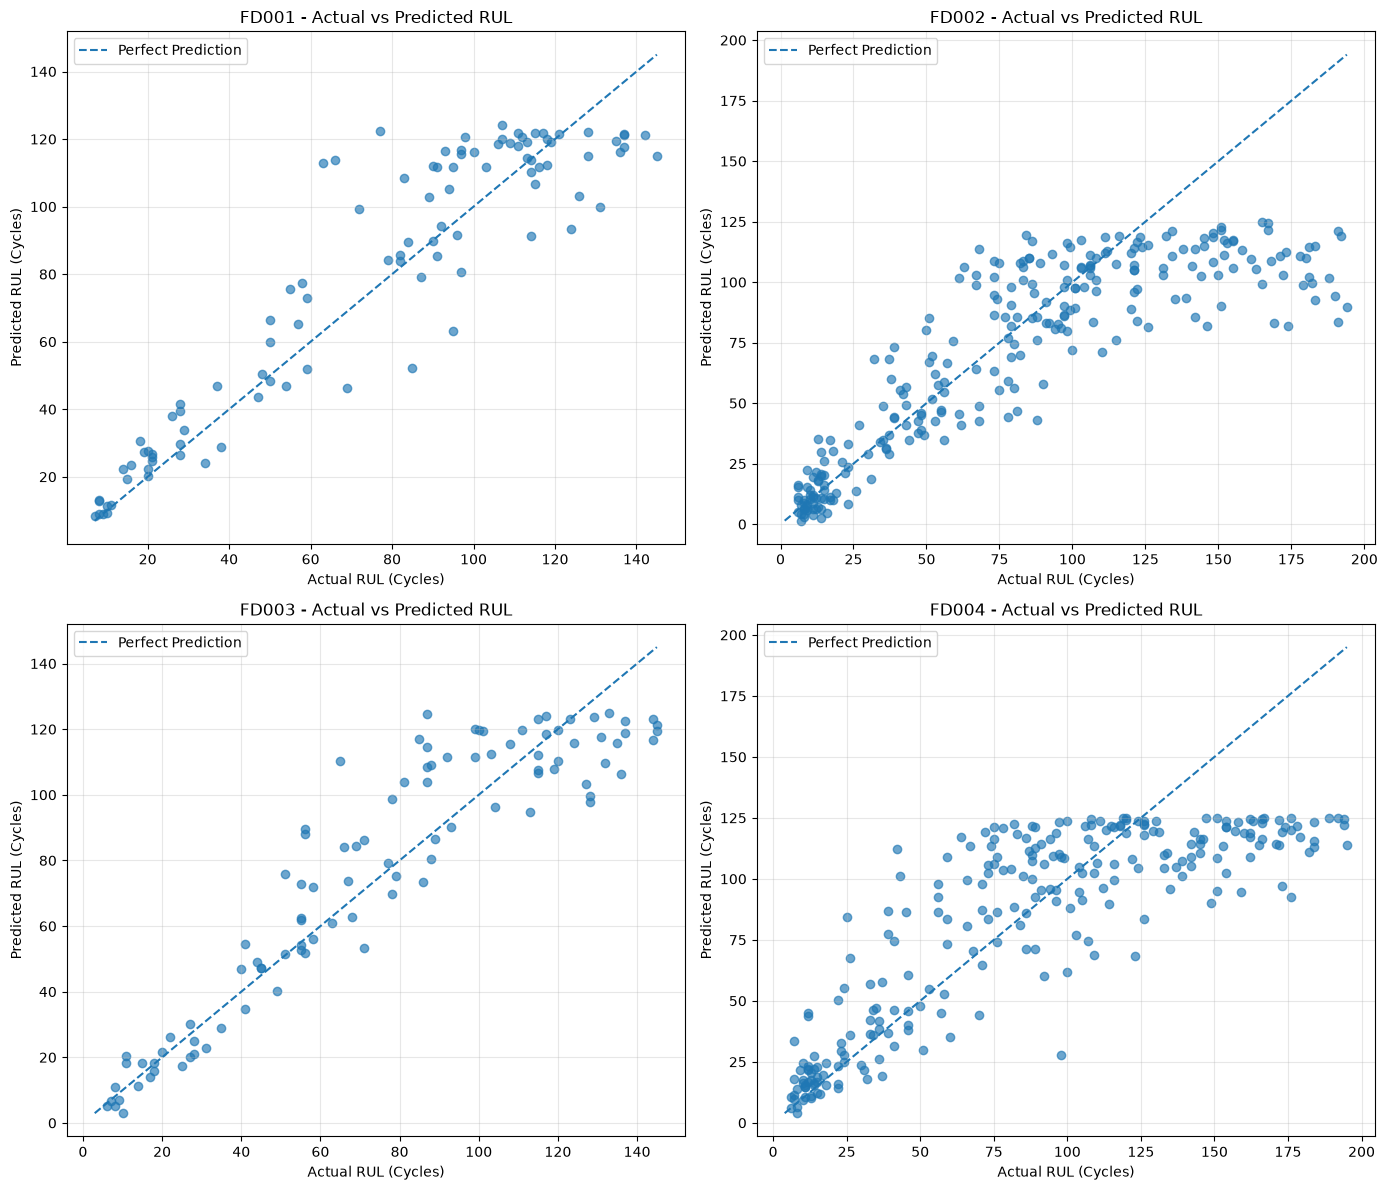

In [8]:
# Step 9: Actual vs Predicted RUL plots

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, fd in zip(axes.flat, test_predictions):

    actual = test_data[fd]["y_test"]
    predicted = test_predictions[fd]

    # Scatter plot
    ax.scatter(
        actual,
        predicted,
        alpha=0.65
    )

    # Perfect prediction reference line
    min_value = min(actual.min(), predicted.min())
    max_value = max(actual.max(), predicted.max())

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--",
        label="Perfect Prediction"
    )

    ax.set_title(f"{fd} - Actual vs Predicted RUL")
    ax.set_xlabel("Actual RUL (Cycles)")
    ax.set_ylabel("Predicted RUL (Cycles)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "multi_dataset_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

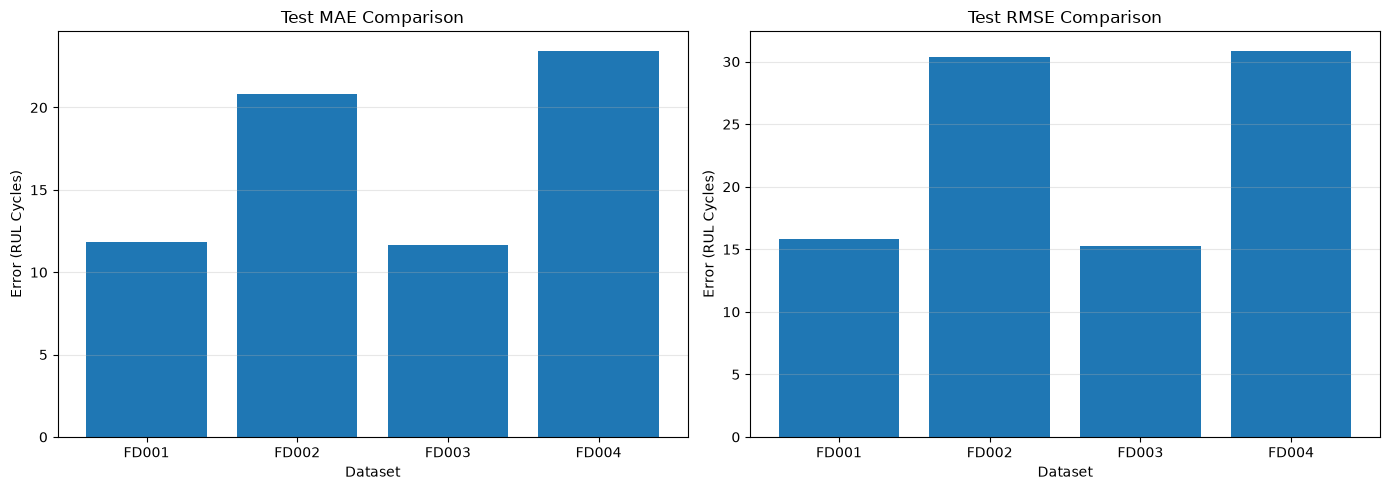

In [9]:
# Step 10: Compare final test MAE and RMSE

metrics = ["Test_MAE", "Test_RMSE"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, metrics):

    ax.bar(
        final_results_df["Dataset"],
        final_results_df[metric]
    )

    ax.set_title(f"{metric.replace('_', ' ')} Comparison")
    ax.set_xlabel("Dataset")
    ax.set_ylabel("Error (RUL Cycles)")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "multi_dataset_test_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

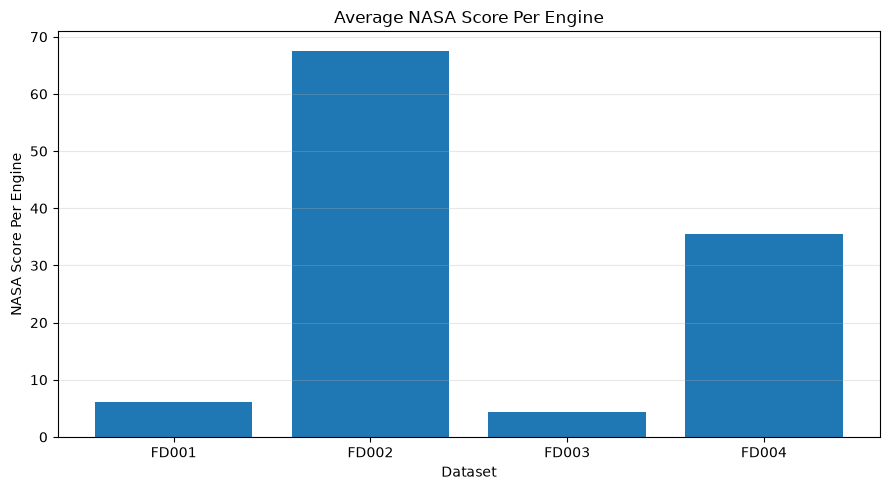

,Dataset,NASA_Score,NASA_Score_Per_Engine
0,FD001,605.594177,6.0559
1,FD002,17501.816406,67.5746
2,FD003,429.313812,4.2931
3,FD004,8818.849609,35.5599


In [10]:
# Step 11: Compare average NASA score per engine

final_results_df["NASA_Score_Per_Engine"] = (
    final_results_df["NASA_Score"] /
    final_results_df["Dataset"].map(
        {fd: len(test_data[fd]["y_test"]) for fd in test_data}
    )
)

plt.figure(figsize=(9, 5))

plt.bar(
    final_results_df["Dataset"],
    final_results_df["NASA_Score_Per_Engine"]
)

plt.title("Average NASA Score Per Engine")
plt.xlabel("Dataset")
plt.ylabel("NASA Score Per Engine")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "multi_dataset_nasa_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(
    final_results_df[
        ["Dataset", "NASA_Score", "NASA_Score_Per_Engine"]
    ].round(4)
)

In [11]:
# Step 12: Save complete final evaluation results

final_results_df.to_csv(
    METRICS_DIR / "multi_dataset_final_test_results.csv",
    index=False
)

print("Complete evaluation results saved!")

display(final_results_df.round(4))

print("\nSaved plots:")
print("1. multi_dataset_actual_vs_predicted.png")
print("2. multi_dataset_test_metrics.png")
print("3. multi_dataset_nasa_score.png")

Complete evaluation results saved!


,Dataset,Model,Test_MAE,Test_RMSE,NASA_Score,NASA_Score_Per_Engine
0,FD001,BiLSTM,11.8172,15.8271,605.594177,6.0559
1,FD002,BiLSTM,20.8118,30.3868,17501.816406,67.5746
2,FD003,Transformer,11.6602,15.2632,429.313812,4.2931
3,FD004,Transformer,23.4507,30.8792,8818.849609,35.5599



Saved plots:
1. multi_dataset_actual_vs_predicted.png
2. multi_dataset_test_metrics.png
3. multi_dataset_nasa_score.png
